In [1]:
import pandas as pd 
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr, spearmanr
import random
from scipy import stats
import matplotlib.pyplot as plt
import itertools
import numpy as np
import time
import os
import tqdm
import pandas as pd
import statsmodels.formula.api as smf
import warnings
from statsmodels.tools.sm_exceptions import (
    ConvergenceWarning,
    SingularMatrixWarning,
)

figure_dir="/home/jhu/jkim789/projects_aphill27/projects/pooch/figures"

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
import seaborn as sns
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

In [2]:
mode = "putative_icr"

In [3]:
import pandas as pd
import numpy as np

BASE = "/path/to/project/pooch/findings/xist"

SWAP_SAMPLES = ["HG03579", "HG02717", "HG02451"]


def correct_haplotype(df):
    """
    Swap maternal/paternal methylation fractions for specified samples.
    Remove (sample, region) pairs without both haplotypes
    only for swap samples.
    """
    df = df.copy()

    df["hap"] = df["hap"].replace({
        1: "Paternal",
        2: "Maternal"
    })

    df["frac_corrected"] = df["frac"]

    mask = df["sample"].isin(SWAP_SAMPLES)

    if not mask.any():
        return df

    sub = df.loc[mask].copy()
    unchanged = df.loc[~mask].copy()

    # Detect duplicate sample-region-haplotype combinations
    keys = ["sample", "id", "hap"]

    if sub.duplicated(keys).any():
        raise ValueError(
            "Duplicate (sample, id, hap) combinations found "
            "before haplotype correction."
        )

    # Pivot to align maternal/paternal by sample and region
    wide = sub.pivot(
        index=["sample", "id"],
        columns="hap",
        values="frac"
    )

    wide = wide.reindex(
        columns=["Maternal", "Paternal"]
    )

    # Only retain complete pairs
    valid_pairs = wide.dropna(
        subset=["Maternal", "Paternal"]
    ).index

    n_before = sub[["sample", "id"]].drop_duplicates().shape[0]
    n_after = len(valid_pairs)

    print(
        f"Removing {n_before - n_after} incomplete "
        f"sample-region pairs from swapped samples"
    )

    # Keep rows with valid pairs
    sub = (
        sub.set_index(["sample", "id"])
        .loc[valid_pairs]
        .reset_index()
    )

    # Swap methylation values while preserving haplotype labels
    opposite = {
        "Maternal": "Paternal",
        "Paternal": "Maternal"
    }

    sub["frac_corrected"] = [
        wide.loc[(sample, region), opposite[hap]]
        for sample, region, hap
        in zip(sub["sample"], sub["id"], sub["hap"])
    ]

    return pd.concat(
        [unchanged, sub],
        ignore_index=True
    )


def read_random_regions(mode):

    print(f"Reading random regions for mode: {mode}")

    valid_modes = [
        "promoter_XIST",
        "dhrsx_region",
        "putative_icr",
        "all_cpg"
    ]

    if mode not in valid_modes:
        raise ValueError(f"Unknown mode: {mode}")

    # ----------------------------------------
    # 1. Read promoter annotations
    # ----------------------------------------

    chrX_promoter = pd.read_csv(
        f"{BASE}/chrX_promoter.mrg.bed",
        sep="\t",
        header=None,
        names=[
            "chr", "start", "end",
            "transcript", "gene", "biotype"
        ]
    )

    chrX_promoter["id"] = (
        chrX_promoter["chr"] + ":" +
        chrX_promoter["start"].astype(str) + "-" +
        chrX_promoter["end"].astype(str)
    )

    # ----------------------------------------
    # 2. Read promoter methylation
    # ----------------------------------------

    df_chrx = pd.read_csv(
        f"{BASE}/chrX_promoter.methylation.bed",
        sep="\t",
        header=None,
        names=[
            "chr", "start", "end",
            "cpg_count", "total", "meth",
            "sample", "hap"
        ]
    )

    df_chrx["frac"] = (
        df_chrx["meth"] /
        df_chrx["total"].replace(0, np.nan)
    )

    df_chrx["id"] = (
        df_chrx["chr"] + ":" +
        df_chrx["start"].astype(str) + "-" +
        df_chrx["end"].astype(str)
    )

    # Filter regions with average CpG count > 5
    valid_ids = (
        df_chrx.groupby("id")["cpg_count"]
        .mean()
        .loc[lambda x: x > 5]
        .index
    )

    df_chrx = df_chrx[
        df_chrx["id"].isin(valid_ids)
    ].copy()

    df_chrx = correct_haplotype(df_chrx)

    # Preserve distinct transcript annotations
    df_chrx = df_chrx.merge(
        chrX_promoter[
            ["id", "gene", "transcript"]
        ].drop_duplicates(),
        on="id",
        how="left"
    )

    df_chrx["id_gene"] = (
        df_chrx["id"] + ":" +
        df_chrx["gene"].fillna("Unknown")
    )

    # ----------------------------------------
    # 3. Promoter mode
    # ----------------------------------------

    if mode == "promoter_XIST":
        return df_chrx

    # XIST promoter for other modes
    df_xist = df_chrx[
        df_chrx["gene"] == "XIST"
    ].copy()

    # ----------------------------------------
    # 4. DHRSX-matched random regions
    # ----------------------------------------

    columns = [
        "chr", "start", "end",
        "tmp", "total", "meth",
        "sample", "hap"
    ]

    if mode == "dhrsx_region":

        df1 = pd.read_csv(
            f"{BASE}/chrX_balance.bed",
            sep="\t",
            header=None,
            names=columns
        )

        df = pd.read_csv(
            f"{BASE}/chrX_DHRSX_matched_regions.fixed.methylation.bed",
            sep="\t",
            header=None,
            names=columns
        )

        df = pd.concat(
            [
                df1.loc[df1["start"] == 1937651],
                df
            ],
            ignore_index=True
        )

        df["frac"] = (
            df["meth"] /
            df["total"].replace(0, np.nan)
        )

    # ----------------------------------------
    # 5. Putative ICR regions
    # ----------------------------------------

    elif mode == "putative_icr":

        df = pd.read_csv(
            "/path/to/project/pooch/"
            "findings/putative_icr_chrX/"
            "putative_ICRs_35_65_final.chm13.methylation.bed",
            sep="\t",
            header=None,
            names=columns
        )

        df["frac"] = (
            df["meth"] /
            df["total"].replace(0, np.nan)
        )

    # ----------------------------------------
    # 6. Individual CpG mode
    # ----------------------------------------

    elif mode == "all_cpg":

        met = pd.read_csv(
            "/path/to/project/pooch/"
            "pooch_data/07.models_using_DSS_insideCV/"
            "chrX.missingrate_5.createMethylDataset.balance.out",
            sep="\t",
            header=0
        )

        df = met.melt(
            id_vars=["Label", "Sample"],
            var_name="cpg",
            value_name="frac"
        ).dropna(subset=["frac"])

        df = df.rename(
            columns={
                "Label": "hap",
                "Sample": "sample"
            }
        )

        df["chr"] = "chrX"

        df["start"] = pd.to_numeric(
            df["cpg"]
        ).astype(int)

        df["end"] = df["start"] + 1

        df["total"] = np.nan
        df["meth"] = np.nan

    # ----------------------------------------
    # 7. Common processing
    # ----------------------------------------

    df["id"] = (
        df["chr"] + ":" +
        df["start"].astype(str) + "-" +
        df["end"].astype(str)
    )

    df = correct_haplotype(df)

    # Assign unique region names
    ids = df["id"].dropna().unique()

    region_df = pd.DataFrame({
        "id": ids,
        "gene": [
            f"region_{i}" for i in range(len(ids))
        ]
    })

    df = df.merge(
        region_df,
        on="id",
        how="left",
        validate="many_to_one"
    )

    df["id_gene"] = (
        df["id"] + ":" + df["gene"]
    )

    # ----------------------------------------
    # 8. Combine with XIST promoter
    # ----------------------------------------

    output_columns = [
        "chr", "start", "end",
        "gene", "total", "meth",
        "sample", "hap",
        "frac_corrected",
        "id", "id_gene"
    ]

    df = pd.concat(
        [
            df_xist[output_columns],
            df[output_columns]
        ],
        ignore_index=True
    )

    return df

In [4]:
import numpy as np
import pandas as pd
import warnings
import statsmodels.formula.api as smf

from statsmodels.tools.sm_exceptions import ConvergenceWarning


def interaction_calculationg(gene1, gene2, df, min_pairs=5):

    gene1_name = gene1.split(":")[-1]
    gene2_name = gene2.split(":")[-1]

    # -----------------------------------------
    # 1. Select target and XIST regions
    # -----------------------------------------

    df_mrg_linear = (
        df.loc[df["id_gene"].isin([gene1, gene2])]
        .pivot_table(
            index=["sample", "hap"],
            columns="id_gene",
            values="frac_corrected",
            aggfunc="mean"
        )
        .reindex(columns=[gene1, gene2])
        .reset_index()
    )

    # Convert methylation proportions to numeric
    for col in [gene1, gene2]:
        df_mrg_linear[col] = pd.to_numeric(
            df_mrg_linear[col],
            errors="coerce"
        )

    # -----------------------------------------
    # 2. Calculate XIST differential methylation
    # -----------------------------------------

    xist_wide = df_mrg_linear.pivot_table(
        index="sample",
        columns="hap",
        values=gene2,
        aggfunc="mean"
    )

    # Prevent KeyError if one haplotype is absent
    xist_wide = xist_wide.reindex(
        columns=["Maternal", "Paternal"]
    )

    # Only retain samples with paired XIST methylation
    xist_wide = xist_wide.dropna(
        subset=["Maternal", "Paternal"]
    )

    if xist_wide.empty:
        return {
            "region": gene1,
            "n_pair": 0,
            "status": "No paired XIST methylation"
        }

    xist_diff = (
        xist_wide["Maternal"] -
        xist_wide["Paternal"]
    ).rename("target2_diff")

    # -----------------------------------------
    # 3. Prepare mixed model dataframe
    # -----------------------------------------

    model_df = (
        df_mrg_linear
        .join(xist_diff, on="sample")
        .dropna(
            subset=[
                "sample",
                "hap",
                gene1,
                "target2_diff"
            ]
        )
        .copy()
    )

    model_df["target_gene"] = model_df[gene1]

    # Only retain samples with both maternal and paternal
    paired = (
        model_df.groupby("sample")["hap"]
        .transform("nunique")
        .eq(2)
    )

    model_df = model_df.loc[paired].copy()

    n_pairs = model_df["sample"].nunique()

    if n_pairs < min_pairs:
        return {
            "region": gene1,
            "n_pair": n_pairs,
            "status": "Insufficient paired samples"
        }

    # Check XIST differential methylation variation
    if model_df["target2_diff"].nunique() < 2:
        return {
            "region": gene1,
            "n_pair": n_pairs,
            "status": "No XIST differential methylation variation"
        }

    # -----------------------------------------
    # 4. Fit linear mixed-effects model
    # -----------------------------------------

    formula = (
        'target_gene ~ '
        'C(hap, Treatment(reference="Paternal")) '
        '* target2_diff'
    )

    try:
        with warnings.catch_warnings():
            warnings.simplefilter(
                "ignore",
                ConvergenceWarning
            )

            model = smf.mixedlm(
                formula=formula,
                data=model_df,
                groups=model_df["sample"]
            ).fit(reml=False)

    except (ValueError, np.linalg.LinAlgError) as e:
        return {
            "region": gene1,
            "n_pair": n_pairs,
            "status": f"Model fitting failed: {str(e)}"
        }

    # -----------------------------------------
    # 5. Extract model statistics
    # -----------------------------------------

    row = {}

    summary = model.summary()

    # Extract model information
    for _, values in summary.tables[0].iterrows():

        for j in range(0, len(values) - 1, 2):

            key = str(values.iloc[j]).strip().rstrip(":")

            if key and key.lower() != "nan":
                row[key] = values.iloc[j + 1]

    # Full precision coefficients and statistics
    conf_int = model.conf_int()

    for term in model.fe_params.index:

        row[f"{term}_Coef."] = model.fe_params[term]
        row[f"{term}_Std.Err."] = model.bse[term]
        row[f"{term}_z"] = model.tvalues[term]
        row[f"{term}_P>|z|"] = model.pvalues[term]

        row[f"{term}_[0.025"] = conf_int.loc[term].iloc[0]
        row[f"{term}_0.975]"] = conf_int.loc[term].iloc[1]

    # -----------------------------------------
    # 6. Add region information
    # -----------------------------------------

    row["y_gene"] = gene1_name
    row["interaction_gene"] = gene2_name

    row["y_id"] = gene1
    row["interaction_gene_id"] = gene2

    row["n_pair"] = n_pairs
    row["status"] = (
        "Success" if model.converged
        else "Not converged"
    )

    return row

In [5]:
def post_process(results_df):
    from statsmodels.stats.multitest import multipletests

    # Boolean True와 문자열 "Yes"/"True" 모두 처리
    # Fixed: Added "else x" so it returns the original name if it's not a string or doesn't match
    results_df = results_df.rename(
        columns=lambda x: x.replace('C(hap, Treatment(reference="Paternal"))[T.Maternal]', 'haplotype') if isinstance(x, str) else x
    )

    converged = (
        results_df["Converged"]
        .astype(str).str.strip().str.lower()
        .isin(["true", "yes", "1", "1.0"])
    )

    # Summary에서 생성한 실제 p-value column을 자동으로 찾기
    p_columns = [
        col for col in results_df.columns
        if col.endswith("_P>|z|")
    ]

    for p_col in p_columns:
        term = p_col.removesuffix("_P>|z|")
        fdr_col = f"{term}_fdr"

        p = pd.to_numeric(results_df[p_col], errors="coerce")
        valid = converged & p.between(0, 1)

        results_df[fdr_col] = np.nan

        if valid.any():
            results_df.loc[valid, fdr_col] = multipletests(
                p.loc[valid].to_numpy(),
                method="fdr_bh"
            )[1]

    results_df = results_df.loc[~results_df['y_id'].isna()]
    # Fixed: Use .str[1] and .str[0] to access elements within the split columns
    results_df['pos'] = results_df['y_id'].str.split(":").str[1].str.split("-").str[0].astype(int)

    # This line is perfectly correct (assuming 'haplotype_fdr' exists and has no zeros)
    for term in [
        "haplotype", "Intercept",
        "target2_diff", "haplotype:target2_diff"
    ]:
        for suffix in ["fdr", "P>|z|"]:
            col = f"{term}_{suffix}"

            values = pd.to_numeric(results_df[col], errors="coerce")
            valid = np.isfinite(values) & values.gt(0) & values.le(1)

            results_df[f"-log_{col}"] = -np.log10(values.where(valid))
    
    return results_df

In [6]:
df = read_random_regions(mode)
df.head(2)

balance_samples = pd.read_csv("/path/to/project/pooch/pooch_data/05.dss_using_123_pairing_chrX_balance/balance.sample.list",
                              header = None, names = ['sample'])
balance_samples = set(balance_samples['sample'])

df = df.loc[df['sample'].isin(balance_samples)]
# balance_samples

Reading random regions for mode: putative_icr
Removing 4 incomplete sample-region pairs from swapped samples
Removing 0 incomplete sample-region pairs from swapped samples


In [7]:
len(set(df['sample']))

50

In [8]:
if os.path.exists(f'/home/jhu/jkim789/projects_aphill27/projects/pooch/findings/xist/{mode}_results.csv'):
    results_df = pd.read_csv(f'/home/jhu/jkim789/projects_aphill27/projects/pooch/findings/xist/{mode}_results.csv', sep = '\t')
    print(f"Loaded existing results for mode: {mode}")
    results_df.head(2)
else:
    print(f"No existing results found for mode: {mode}. Starting new calculations.")
    xist_id = "chrX:72285969-72286319:XIST"

    gene_ids = sorted(
        set(df["id_gene"].dropna()) - {xist_id}
    )

    all_results = []

    for gene1 in tqdm.tqdm(gene_ids):
        all_results.append(
            interaction_calculationg(gene1, xist_id, df)
        )

    results_df = pd.DataFrame(all_results)
    results_df = post_process(results_df)

    results_df.to_csv(f'/home/jhu/jkim789/projects_aphill27/projects/pooch/findings/xist/{mode}_results.csv', index=False, sep = '\t')
    results_df.head(2)

Loaded existing results for mode: putative_icr


In [9]:
with pd.option_context(
    # "display.max_rows", None,
    "display.max_columns", None
):
    display(results_df)

,Model,Dependent Variable,No. Observations,Method,No. Groups,Scale,Min. group size,Log-Likelihood,Max. group size,Converged,Mean group size,Intercept_Coef.,Intercept_Std.Err.,Intercept_z,Intercept_P>|z|,Intercept_[0.025,Intercept_0.975],haplotype_Coef.,haplotype_Std.Err.,haplotype_z,haplotype_P>|z|,haplotype_[0.025,haplotype_0.975],target2_diff_Coef.,target2_diff_Std.Err.,target2_diff_z,target2_diff_P>|z|,target2_diff_[0.025,target2_diff_0.975],haplotype:target2_diff_Coef.,haplotype:target2_diff_Std.Err.,haplotype:target2_diff_z,haplotype:target2_diff_P>|z|,haplotype:target2_diff_[0.025,haplotype:target2_diff_0.975],y_gene,interaction_gene,y_id,interaction_gene_id,n_pair,status,Intercept_fdr,haplotype_fdr,target2_diff_fdr,haplotype:target2_diff_fdr,pos,-log_haplotype_fdr,-log_haplotype_P>|z|,-log_Intercept_fdr,-log_Intercept_P>|z|,-log_target2_diff_fdr,-log_target2_diff_P>|z|,-log_haplotype:target2_diff_fdr,-log_haplotype:target2_diff_P>|z|
0,MixedLM,target_gene,96,ML,48,0.0049,2,109.0811,2,Yes,2.0,0.658218,0.011379,57.844669,0.000000e+00,0.635916,0.680521,-0.035136,0.014356,-2.447593,0.014381,-0.063273,-0.007000,0.067145,0.028034,2.395122,1.661486e-02,0.012199,0.122090,-0.080063,0.035367,-2.263802,2.358630e-02,-0.149381,-0.010746,region_50,XIST,chrX:100585560-100586120:region_50,chrX:72285969-72286319:XIST,48,Success,0.000000e+00,0.206133,2.381463e-02,2.856932e-02,100585560,0.685852,1.842199,NaN,NaN,1.623156,1.779503,1.544100,1.627340
1,MixedLM,target_gene,98,ML,49,0.0125,2,58.9658,2,Yes,2.0,0.594362,0.019550,30.402172,5.141586e-203,0.556045,0.632680,-0.009450,0.022684,-0.416593,0.676976,-0.053909,0.035009,0.149212,0.048614,3.069346,2.145281e-03,0.053931,0.244494,-0.298842,0.056406,-5.298051,1.170453e-07,-0.409396,-0.188288,region_51,XIST,chrX:100916516-100916655:region_51,chrX:72285969-72286319:XIST,49,Success,6.802714e-203,0.879434,3.925408e-03,2.236866e-07,100916516,0.055797,0.169427,202.167318,202.288903,2.406115,2.668516,6.650360,6.931646
2,MixedLM,target_gene,98,ML,49,0.0144,2,56.4055,2,Yes,2.0,0.700226,0.019818,35.332153,1.884828e-273,0.661382,0.739069,-0.044268,0.024319,-1.820317,0.068711,-0.091931,0.003396,0.061565,0.049281,1.249266,2.115677e-01,-0.035024,0.158154,-0.189326,0.060472,-3.130835,1.743100e-03,-0.307849,-0.070804,region_52,XIST,chrX:100991665-100991988:region_52,chrX:72285969-72286319:XIST,49,Success,2.947185e-273,0.347595,2.675709e-01,2.399613e-03,100991665,0.458926,1.162976,272.530593,272.724728,0.572561,0.674551,2.619859,2.758678
3,MixedLM,target_gene,98,ML,49,0.0035,2,126.2062,2,Yes,2.0,0.769340,0.009714,79.199048,0.000000e+00,0.750301,0.788379,0.005142,0.011968,0.429656,0.667446,-0.018314,0.028599,-0.059724,0.024155,-2.472488,1.341761e-02,-0.107067,-0.012380,0.103646,0.029760,3.482760,4.962726e-04,0.045318,0.161973,region_53,XIST,chrX:101668223-101668487:region_53,chrX:72285969-72286319:XIST,49,Success,0.000000e+00,0.879434,1.955787e-02,7.358525e-04,101668223,0.055797,0.175584,NaN,NaN,1.708678,1.872325,3.133209,3.304280
4,MixedLM,target_gene,100,ML,50,0.0134,2,73.6511,2,Yes,2.0,0.499753,0.016442,30.395590,6.281832e-203,0.467528,0.531978,0.008090,0.023252,0.347934,0.727889,-0.037483,0.053663,0.306110,0.041299,7.412137,1.242805e-13,0.225167,0.387054,-0.559021,0.058405,-9.571479,1.053871e-21,-0.673493,-0.444550,region_54,XIST,chrX:103341184-103341910:region_54,chrX:72285969-72286319:XIST,50,Success,8.185418e-203,0.881669,7.125413e-13,5.331347e-21,103341184,0.054694,0.137935,202.086959,202.201914,12.147190,12.905597,20.273163,20.977213
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,MixedLM,target_gene,100,ML,50,0.0129,2,71.4326,2,Yes,2.0,0.678597,0.016842,40.292900,0.000000e+00,0.645588,0.711605,-0.009757,0.022772,-0.428476,0.668305,-0.054390,0.034876,0.164555,0.042303,3.889891,1.002894e-04,0.081642,0.247467,-0.264850,0.057200,-4.6

In [11]:
results_df.loc[results_df['-log_haplotype_P>|z|'].isna()]

,Model,Dependent Variable,No. Observations,Method,No. Groups,Scale,Min. group size,Log-Likelihood,Max. group size,Converged,...,pos,-log_haplotype_fdr,-log_haplotype_P>|z|,-log_Intercept_fdr,-log_Intercept_P>|z|,-log_target2_diff_fdr,-log_target2_diff_P>|z|,-log_haplotype:target2_diff_fdr,-log_haplotype:target2_diff_P>|z|,dataset


In [12]:
results_df.shape

(94, 55)

In [10]:
# params = ['haplotype', 'Intercept', 'target2_diff', 'haplotype:target2_diff']
params = ['haplotype', 'target2_diff', 'haplotype:target2_diff']
results_df['dataset'] ="random select"
sig_list = results_df.loc[
    results_df["haplotype_fdr"] < 0.05,
    "y_id"
].dropna().to_list()

results_df.loc[results_df['y_id'].isin(sig_list), 'dataset'] = "significant"

results_df = results_df.sort_values(by='dataset', ascending=True)

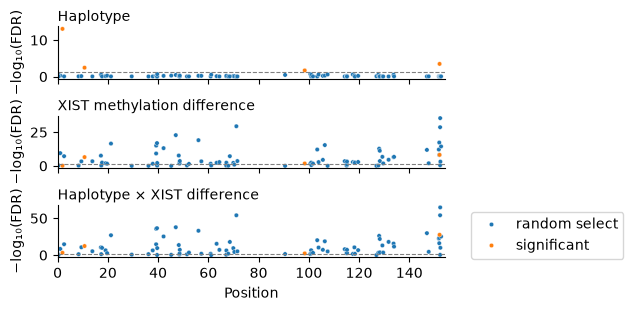

In [21]:

    
results_df['pos_mb'] = results_df['pos'] / 1e6

fig, axes = plt.subplots(
    3, 1,
    figsize=(5, 3),
    sharex=True,
    gridspec_kw={'hspace': 0.7}
)

for ax, p in zip(axes, params):
    sns.scatterplot(
        data=results_df,
        x='pos_mb',
        # y=f"-log_{p}_P>|z|",
        y=f"-log_{p}_fdr",
        ax=ax,
        s=10,
        hue="dataset",
    )
    
    ax.get_legend().remove() 

    ax.set_ylabel(p)
    ax.set_xlabel("")

axes[-1].set_xlabel("Position")

sns.despine()

for ax in axes:
    ax.axhline(
        -np.log10(0.05),
        color='gray',
        linestyle='--',
        linewidth=0.8
    )
    ax.set_xlim(0, 154259566 / 1e6)

titles = [
    "Haplotype",
    "XIST methylation difference",
    "Haplotype × XIST difference"
]

for ax, title in zip(axes, titles):
    ax.set_title(title, loc="left", fontsize=10, pad=4)
    ax.set_ylabel("−log₁₀(FDR)")

fig.subplots_adjust(hspace=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
# plt.savefig(f"{figure_dir}/chrX_interaction_analysis_random_regions_with_DHRSX.pdf", bbox_inches='tight', dpi=300)
plt.savefig(f"{figure_dir}/chrX_interaction_analysis_{mode}.pdf", bbox_inches='tight', dpi=300)
plt.show()

In [23]:
results_df['hap_fdr_sig'] = np.where(results_df['haplotype_fdr'] < 0.05, "yes", "no")
results_df['haplotype:target2_diff_fdr_sig'] = np.where(results_df['haplotype:target2_diff_fdr'] < 0.05, "yes", "no")
results_df['target2_diff_fdr_sig'] = np.where(results_df['target2_diff_fdr'] < 0.05, "yes", "no")

results_df_hap = results_df.loc[results_df['hap_fdr_sig']=="yes", ['y_id','haplotype_fdr','haplotype:target2_diff_fdr','target2_diff_fdr']]
results_df_hap['chr'] = results_df_hap['y_id'].str.split(":").str[0]
results_df_hap['start'] = results_df_hap['y_id'].str.split(":").str[1].str.split("-").str[0].astype(int)
results_df_hap['end'] = results_df_hap['y_id'].str.split(":").str[1].str.split("-").str[1].astype(int)
results_df_hap['empty'] = "."

results_df_hap

,y_id,haplotype_fdr,haplotype:target2_diff_fdr,target2_diff_fdr,chr,start,end,empty
9,chrX:10721280-10721775:region_7,3.655300e-03,4.345774e-13,3.025330e-07,chrX,10721280,10721775,.
37,chrX:152054596-152054831:region_84,3.307336e-04,2.649003e-28,6.724427e-09,chrX,152054596,152054831,.
52,chrX:1937947-1938701:region_3,8.672634e-14,6.993567e-04,7.716812e-01,chrX,1937947,1938701,.
93,chrX:98381847-98382649:region_49,1.992919e-02,4.253827e-03,1.575404e-02,chrX,98381847,98382649,.


In [24]:
# file="/home/jhu/jkim789/projects_aphill27/projects/pooch/findings/xist/hapSpecific_region.bed"
file=f"/home/jhu/jkim789/projects_aphill27/projects/pooch/findings/xist/hapSpecific_from_interactive_{mode}.bed"

results_df_hap[['chr','start','end']].sort_values(['chr','start']).to_csv(file,
                                             sep = "\t", index = False, header = False)

In [25]:
with pd.option_context(
    # "display.max_rows", None,
    "display.max_columns", None
):
    
    display(results_df.loc[results_df["y_id"].str.contains(r"region_0$", na=False)])

,Model,Dependent Variable,No. Observations,Method,No. Groups,Scale,Min. group size,Log-Likelihood,Max. group size,Converged,Mean group size,Intercept_Coef.,Intercept_Std.Err.,Intercept_z,Intercept_P>|z|,Intercept_[0.025,Intercept_0.975],haplotype_Coef.,haplotype_Std.Err.,haplotype_z,haplotype_P>|z|,haplotype_[0.025,haplotype_0.975],target2_diff_Coef.,target2_diff_Std.Err.,target2_diff_z,target2_diff_P>|z|,target2_diff_[0.025,target2_diff_0.975],haplotype:target2_diff_Coef.,haplotype:target2_diff_Std.Err.,haplotype:target2_diff_z,haplotype:target2_diff_P>|z|,haplotype:target2_diff_[0.025,haplotype:target2_diff_0.975],y_gene,interaction_gene,y_id,interaction_gene_id,n_pair,status,Intercept_fdr,haplotype_fdr,target2_diff_fdr,haplotype:target2_diff_fdr,pos,-log_haplotype_fdr,-log_haplotype_P>|z|,-log_Intercept_fdr,-log_Intercept_P>|z|,-log_target2_diff_fdr,-log_target2_diff_P>|z|,-log_haplotype:target2_diff_fdr,-log_haplotype:target2_diff_P>|z|,dataset,pos_mb,hap_fdr_sig,haplotype:target2_diff_fdr_sig,target2_diff_fdr_sig
47,MixedLM,target_gene,96,ML,48,0.0388,2,11.8496,2,Yes,2.0,0.625043,0.031125,20.081416,1.072927e-89,0.564038,0.686047,-0.086212,0.040262,-2.141303,0.03225,-0.165124,-0.007301,0.112835,0.077664,1.452852,0.146265,-0.039384,0.265054,-0.195644,0.100461,-1.947461,0.051479,-0.392543,0.001256,region_0,XIST,chrX:161630-161853:region_0,chrX:72285969-72286319:XIST,48,Success,1.167996e-89,0.252133,0.187743,0.058253,161630,0.59837,1.491476,88.932559,88.96943,0.726436,0.83486,1.234681,1.288366,random select,0.16163,no,no,no


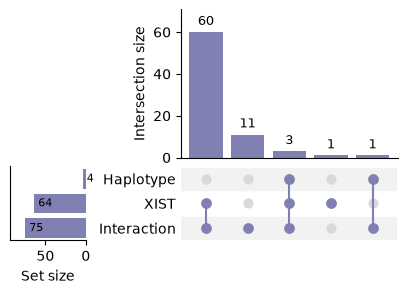

In [26]:
import numpy as np
import matplotlib.pyplot as plt

sig_cols = {
    "hap_fdr_sig": "Haplotype",
    "target2_diff_fdr_sig": "XIST",
    "haplotype:target2_diff_fdr_sig": "Interaction",
}

indicators = (
    results_df[list(sig_cols)]
    .eq("yes")
    .rename(columns=sig_cols)
)

# 하나 이상 유의한 region만 포함
indicators = indicators.loc[indicators.any(axis=1)]

counts = (
    indicators.groupby(list(indicators.columns), observed=True)
    .size()
    .sort_values(ascending=False)
)

if counts.empty:
    print("유의한 region이 없습니다.")

else:
    labels = indicators.columns.tolist()
    membership = np.array(counts.index.tolist(), dtype=bool)
    xs = np.arange(len(counts))
    ys = np.arange(len(labels))
    color = "#8080b2"

    fig = plt.figure(figsize=(5, 3))
    gs = fig.add_gridspec(
        2, 2,
        width_ratios=[1.4, 4],
        height_ratios=[3, 1.5],
        hspace=0.08,
        wspace=0.65
    )

    ax_bar = fig.add_subplot(gs[0, 1])
    ax_matrix = fig.add_subplot(gs[1, 1], sharex=ax_bar)
    ax_total = fig.add_subplot(gs[1, 0], sharey=ax_matrix)

    # 위: 각 교집합의 region 수
    bars = ax_bar.bar(xs, counts.to_numpy(), color=color)
    ax_bar.bar_label(bars, fontsize=9, padding=3)
    ax_bar.set_ylabel("Intersection size")
    ax_bar.tick_params(axis="x", bottom=False, labelbottom=False)
    ax_bar.set_ylim(0, counts.max() * 1.18)

    # 아래: 교집합 조합
    for j in ys:
        ax_matrix.axhspan(
            j - 0.45, j + 0.45,
            color="#f2f2f2" if j % 2 == 0 else "white",
            zorder=0
        )

    for i, included in enumerate(membership):
        ax_matrix.scatter(
            np.full(len(labels), i), ys,
            color="#d9d9d9", s=40, zorder=2
        )

        active = ys[included]

        ax_matrix.scatter(
            np.full(len(active), i), active,
            color=color, s=45, zorder=3
        )

        if len(active) > 1:
            ax_matrix.plot(
                [i, i], [active.min(), active.max()],
                color=color, linewidth=1.5, zorder=2
            )

    ax_matrix.set_yticks(ys)
    ax_matrix.set_yticklabels(labels)
    ax_matrix.set_ylim(len(labels) - 0.5, -0.5)
    ax_matrix.set_xlim(-0.6, len(counts) - 0.4)
    ax_matrix.tick_params(axis="both", length=0)
    ax_matrix.tick_params(axis="x", labelbottom=False)

    # 왼쪽: 각 그룹의 전체 region 수
    totals = indicators.sum().reindex(labels).to_numpy()
    total_bars = ax_total.barh(ys, totals, color=color)

    ax_total.bar_label(total_bars, fontsize=8, padding=3)
    ax_total.set_xlim(max(totals) * 1.25, 0)
    ax_total.set_xlabel("Set size")
    ax_total.tick_params(axis="y", left=False, labelleft=False)

    for ax in [ax_bar, ax_matrix, ax_total]:
        ax.grid(False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    ax_matrix.spines["left"].set_visible(False)
    ax_matrix.spines["bottom"].set_visible(False)
    plt.savefig(f"{figure_dir}/haplotype_specific_regions_{mode}.pdf", bbox_inches='tight', dpi=300)
    plt.show()

In [27]:

with pd.option_context(
    # "display.max_rows", None,
    "display.max_columns", None
):
    display(results_df.sort_values(by = "-log_haplotype_P>|z|", ascending=False)
)

,Model,Dependent Variable,No. Observations,Method,No. Groups,Scale,Min. group size,Log-Likelihood,Max. group size,Converged,Mean group size,Intercept_Coef.,Intercept_Std.Err.,Intercept_z,Intercept_P>|z|,Intercept_[0.025,Intercept_0.975],haplotype_Coef.,haplotype_Std.Err.,haplotype_z,haplotype_P>|z|,haplotype_[0.025,haplotype_0.975],target2_diff_Coef.,target2_diff_Std.Err.,target2_diff_z,target2_diff_P>|z|,target2_diff_[0.025,target2_diff_0.975],haplotype:target2_diff_Coef.,haplotype:target2_diff_Std.Err.,haplotype:target2_diff_z,haplotype:target2_diff_P>|z|,haplotype:target2_diff_[0.025,haplotype:target2_diff_0.975],y_gene,interaction_gene,y_id,interaction_gene_id,n_pair,status,Intercept_fdr,haplotype_fdr,target2_diff_fdr,haplotype:target2_diff_fdr,pos,-log_haplotype_fdr,-log_haplotype_P>|z|,-log_Intercept_fdr,-log_Intercept_P>|z|,-log_target2_diff_fdr,-log_target2_diff_P>|z|,-log_haplotype:target2_diff_fdr,-log_haplotype:target2_diff_P>|z|,dataset,pos_mb,hap_fdr_sig,haplotype:target2_diff_fdr_sig,target2_diff_fdr_sig
52,MixedLM,target_gene,100,ML,50,0.0091,2,66.4267,2,Yes,2.0,0.245173,0.018939,12.945314,2.497401e-38,0.208053,0.282293,0.153269,0.019097,8.025827,1.008446e-15,0.115839,0.190698,-0.017762,0.047572,-0.373374,7.088700e-01,-0.111001,0.075477,-0.167936,0.047968,-3.500994,4.635271e-04,-0.261952,-0.073920,region_3,XIST,chrX:1937947-1938701:region_3,chrX:72285969-72286319:XIST,50,Success,2.526782e-38,8.672634e-14,7.716812e-01,6.993567e-04,1937947,13.061849,14.996347,37.597432,37.602512,0.112562,0.149433,3.155301,3.333925,significant,1.937947,yes,yes,no
37,MixedLM,target_gene,100,ML,50,0.0193,2,55.1345,2,Yes,2.0,0.640581,0.019786,32.374638,6.245488e-230,0.601800,0.679362,-0.124666,0.027867,-4.473597,7.691479e-06,-0.179284,-0.070047,0.300072,0.049700,6.037643,1.563820e-09,0.202662,0.397483,-0.786355,0.069997,-11.234127,2.772212e-29,-0.923547,-0.649164,region_84,XIST,chrX:152054596-152054831:region_84,chrX:72285969-72286319:XIST,50,Success,9.103593e-230,3.307336e-04,6.724427e-09,2.649003e-28,152054596,3.480522,5.113990,229.040787,229.204434,8.172345,8.805813,27.576918,28.557174,significant,152.054596,yes,yes,yes
9,MixedLM,target_gene,100,ML,50,0.0127,2,69.0168,2,Yes,2.0,0.552931,0.017319,31.925972,1.164693e-223,0.518986,0.586876,0.086538,0.022588,3.831218,1.275105e-04,0.042267,0.130809,0.231569,0.043503,5.323094,1.020169e-07,0.146305,0.316833,-0.419558,0.056736,-7.394923,1.414903e-13,-0.530759,-0.308358,region_7,XIST,chrX:10721280-10721775:region_7,chrX:72285969-72286319:XIST,50,Success,1.615542e-223,3.655300e-03,3.025330e-07,4.345774e-13,10721280,2.437077,3.894454,222.791682,222.933789,6.519227,6.991328,12.361933,12.849273,significant,10.721280,yes,yes,yes
93,MixedLM,target_gene,100,ML,50,0.0072,2,99.7927,2,Yes,2.0,0.606934,0.012695,47.808086,0.000000e+00,0.582052,0.631816,0.056221,0.016976,3.311812,9.269389e-04,0.022949,0.089492,0.081661,0.031888,2.560850,1.044163e-02,0.019161,0.144160,-0.125839,0.042640,-2.951179,3.165638e-03,-0.209412,-0.042266,region_49,XIST,chrX:98381847-98382649:region_49,chrX:72285969-72286319:XIST,50,Success,0.000000e+00,1.992919e-02,1.575404e-02,4.253827e-03,98381847,1.700510,3.032949,NaN,NaN,1.802608,1.981232,2.371220,2.499539,significant,98.381847,yes,yes,yes
22,MixedLM,target_gene,100,ML,50,0.0096,2,81.4576,2,No,2.0,0.458578,0.015325,29.924084,9.566816e-197,0.428542,0.488614,0.051027,0.019693,2.591124,9.566297e-03,0.012429,0.089625,0.478065,0.038493,12.419528,2.047656e-35,0.402620,0.553510,-0.952823,0.049465,-19.262413,1.110799e-82,-1.049774,-0.855873,region_70,XIST,chrX:128162916-128163439:region_70,chrX:72285969-72286319:XIST,50,Not converged,NaN,NaN,NaN,NaN,128162916,NaN,2.019256,NaN,196.019233,NaN,34.688743,NaN,81.954364,random select,128.162916,no,no,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
